Rows before IQR filtering: 199,257
Rows flagged as outliers: 20,537
Rows after filtering: 178,720


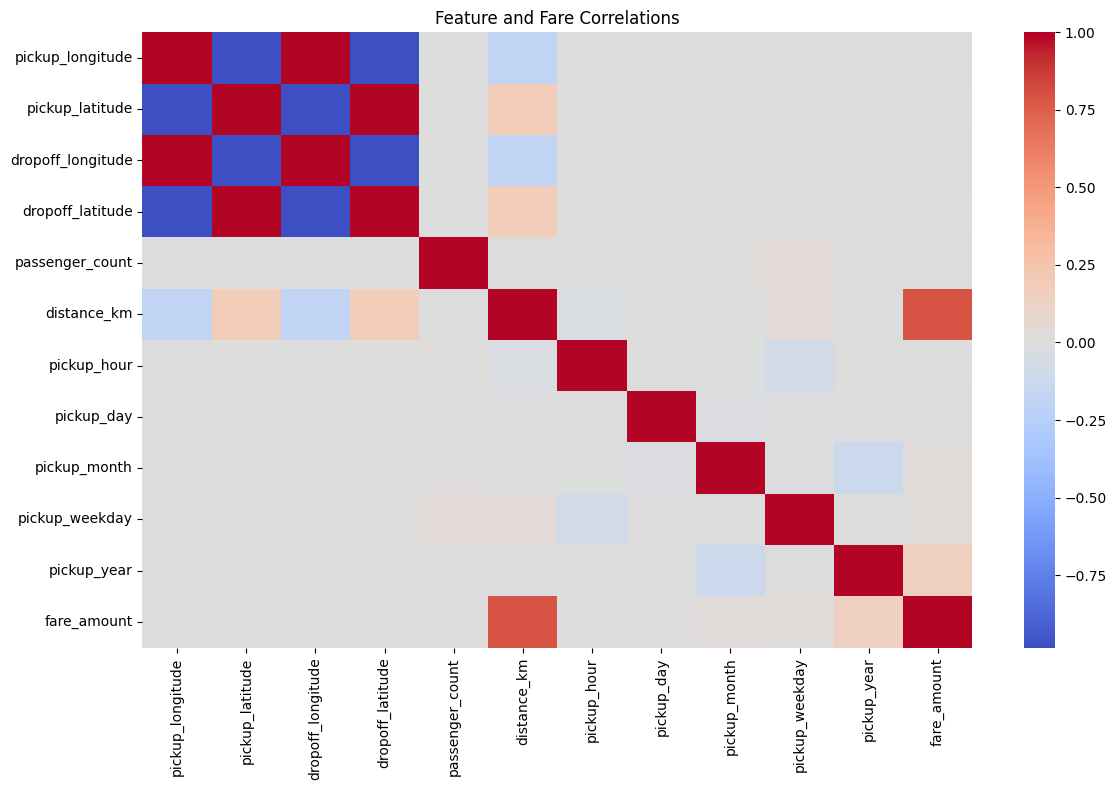

Correlations with fare_amount:
fare_amount          1.000000
distance_km          0.783720
pickup_year          0.156030
pickup_month         0.029026
pickup_weekday       0.017207
passenger_count      0.014562
pickup_day           0.006795
dropoff_longitude    0.005340
pickup_longitude     0.005190
pickup_hour         -0.003096
pickup_latitude     -0.005572
dropoff_latitude    -0.005717
Name: fare_amount, dtype: float64

Model comparison (lower RMSE/MAE is better; higher R2 is better):


,Model,R2,RMSE,MAE
1,Random Forest,0.744313,2.002553,1.361437
0,Linear Regression,0.665649,2.289979,1.618894


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load and clean the data
df = pd.read_csv("uber.csv")
df.columns = df.columns.str.strip().str.lower()

required = {
	"fare_amount", "pickup_datetime", "pickup_longitude", "pickup_latitude",
	"dropoff_longitude", "dropoff_latitude", "passenger_count"
}
missing = required - set(df.columns)
if missing:
	raise ValueError(f"Missing required columns: {missing}")

df = df.drop(columns=[c for c in df.columns if c.startswith("unnamed")], errors="ignore")
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
numeric_cols = [
	"fare_amount", "pickup_longitude", "pickup_latitude",
	"dropoff_longitude", "dropoff_latitude", "passenger_count"
]
for col in numeric_cols:
	df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=numeric_cols + ["pickup_datetime"])
df = df[
	(df["fare_amount"] > 0) &
	df["pickup_longitude"].between(-180, 180) &
	df["dropoff_longitude"].between(-180, 180) &
	df["pickup_latitude"].between(-90, 90) &
	df["dropoff_latitude"].between(-90, 90) &
	(df["passenger_count"] > 0)
].copy()

# Feature engineering: great-circle distance and pickup time components
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_weekday"] = df["pickup_datetime"].dt.dayofweek
df["pickup_year"] = df["pickup_datetime"].dt.year

# Identify outliers using the IQR rule for fare and distance
def iqr_outlier_mask(series):
	q1, q3 = series.quantile([0.25, 0.75])
	iqr = q3 - q1
	return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

fare_outliers = iqr_outlier_mask(df["fare_amount"])
distance_outliers = iqr_outlier_mask(df["distance_km"])
outliers = fare_outliers | distance_outliers
print(f"Rows before IQR filtering: {len(df):,}")
print(f"Rows flagged as outliers: {outliers.sum():,}")

# Remove flagged fare/distance outliers for model training
df = df.loc[~outliers].copy()
print(f"Rows after filtering: {len(df):,}")

# Correlation check
features = [
	"pickup_longitude", "pickup_latitude", "dropoff_longitude",
	"dropoff_latitude", "passenger_count", "distance_km",
	"pickup_hour", "pickup_day", "pickup_month", "pickup_weekday", "pickup_year"
]
corr = df[features + ["fare_amount"]].corr(numeric_only=True)
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature and Fare Correlations")
plt.tight_layout()
plt.show()

print("Correlations with fare_amount:")
print(corr["fare_amount"].sort_values(ascending=False))

# Train/test split
X = df[features]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(
	X, y, test_size=0.2, random_state=42
)

models = {
	"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
	"Random Forest": RandomForestRegressor(
		n_estimators=100, max_depth=20, min_samples_leaf=2,
		random_state=42, n_jobs=-1
	)
}

# Fit and compare models
results = []
for name, model in models.items():
	model.fit(X_train, y_train)
	predictions = model.predict(X_test)
	results.append({
		"Model": name,
		"R2": r2_score(y_test, predictions),
		"RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
		"MAE": mean_absolute_error(y_test, predictions)
	})

results_df = pd.DataFrame(results).sort_values("RMSE")
print("\nModel comparison (lower RMSE/MAE is better; higher R2 is better):")
display(results_df)